# 02 · Creación de variables

**Objetivo:** construir el tablón analítico con las variables de negocio: precio total por noche, ingresos anuales, coste de adquisición, score turístico, discretizaciones y margen bruto.

**Entrada:** base SQLite del notebook 01. **Salida:** tabla `tablon_analitico` en la misma base.

**Contenido**
1. Configuración y carga desde la base de datos
2. Integración de tablas
3. Filtrado por ocupación
4. Variables de ingresos y coste
5. Score turístico
6. Discretizaciones
7. Margen bruto
8. Guardado del tablón analítico

## 1. Configuración y carga desde la base de datos

In [267]:
# Importación de librerías
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns  
import sqlite3 

In [268]:
# Carga de las tres tablas desde SQLite y comprobación de sus dimensiones
ruta_db = Path("../datos/intermedios/mercado_inmobiliario.db")

with sqlite3.connect(ruta_db) as conn:
    listings = pd.read_sql("SELECT * FROM listings", conn)
    listings_det = pd.read_sql("SELECT * FROM listings_det", conn)
    precio = pd.read_sql("SELECT * FROM idealista_precio_m2", conn)

for nombre, df in {'listings': listings, 'listings_det': listings_det, 'precio': precio}.items():
    print(f"{nombre}: {df.shape}")

listings: (18962, 10)
listings_det: (10431, 8)
precio: (21, 2)


## 2. Integración de tablas

In [269]:
# Inner join entre listings y listings_det por la columna 'id'
df_listings = pd.merge(listings, listings_det, on='id', how='inner')

In [270]:
# Left join con el precio/m² de Idealista por distrito (neighbourhood_group = distrito)
df = pd.merge(df_listings, precio, left_on=['neighbourhood_group'], right_on=['distrito'], how='left')

In [271]:
# Se eliminan columnas redundantes (id y neighbourhood_group)
df = df.drop(columns=['id','neighbourhood_group'])

In [272]:
# Se renombran las columnas: price → precio_noche y precio_m2_sep_2026 → precio_m2_distrito
df = df.rename(columns={'price': 'precio_noche', 'precio_m2_sep_2026': 'precio_m2_distrito'})

## 3. Filtrado por ocupación

In [274]:
# Se conservan los anuncios con al menos 100 días de ocupación estimada
df = df[df['estimated_occupancy_l365d'] >= 100]

## 4. Variables de ingresos y coste

### 4.1 Precio total por noche

Para habitaciones privadas y compartidas, el precio publicado es por habitación o por plaza. Se calcula el precio del inmueble completo, aplicando una tasa del 50% cuando hay más de una unidad para reflejar que no se alquilan todas a la vez.

In [275]:
# precio_noche_total: precio del inmueble completo según el tipo de alojamiento
tasa = 0.5

condiciones = [
    df.room_type == 'Entire home/apt',
    (df.room_type == 'Private room')&(df['bedrooms']==1),
    (df.room_type == 'Private room')&(df['bedrooms']>1),
    (df.room_type == 'Shared room')&(df['accommodates']==1),
    (df.room_type == 'Shared room')&(df['accommodates']>1)
]

valores = [
    df.precio_noche,
    df.precio_noche * df.bedrooms,
    df.precio_noche * df.bedrooms * tasa,
    df.precio_noche * df.accommodates,
    df.precio_noche * df.accommodates * tasa,
]

df['precio_noche_total'] = np.select(condiciones, valores, default=np.nan)

### 4.2 Ingresos anuales

In [276]:
# ingresos_anuales = precio_noche_total × ocupación estimada de 365 días
df['ingresos_anuales'] = df['precio_noche_total'] * df['estimated_occupancy_l365d']

### 4.3 Superficie estimada

In [277]:
# m2_estimado: superficie estimada según número de habitaciones y baños
condiciones_m2 =[
    (df['bedrooms']<=1),
    (df['bedrooms']==2),
    (df['bedrooms'] == 3) & (df['bathrooms'] < 2),
    (df['bedrooms'] == 3) & (df['bathrooms'] >= 2),
    (df['bedrooms'] >= 4) & (df['bathrooms'] < 3),    
    (df['bedrooms'] >= 4) & (df['bathrooms'] >= 3),
]

valores_m2 = [50, 65, 90, 110, 120, 140]

df['m2_estimado']=np.select(condiciones_m2,valores_m2,default=np.nan)

### 4.4 Coste de adquisición

In [278]:
# coste_adquisicion = m² estimados × precio/m² del distrito × 0,75
# (ajuste del 25% por descuento de compra y mobiliario)
df['coste_adquisicion'] = df['m2_estimado'] * df['precio_m2_distrito']*0.75 #25% de descuento por el equipo de trabajo y la compra de mobiliario, etc.

In [279]:
# Coste de adquisición medio por distrito (de mayor a menor)
df.groupby('distrito')['coste_adquisicion'].mean().reset_index().sort_values('coste_adquisicion', ascending=False)

,distrito,coste_adquisicion
14,Salamanca,528815.477749
5,Chamberí,419378.616071
13,Retiro,413983.040201
4,Chamartín,360158.556630
3,Centro,352947.880377
10,Moncloa - Aravaca,286324.891304
0,Arganzuela,286164.782609
16,Tetuán,281512.934113
7,Fuencarral - El Pardo,257677.500000
11,Moratalaz,250594.166667


## 5. Score turístico

Mide la cercanía de cada inmueble a 20 puntos de interés turístico de Madrid, ponderados por importancia, dentro de un radio de 5 km. La función está en `funciones/funciones.py`. Escala de 0 a 100.

In [280]:
# score_turistico a partir de las funciones de funciones.py
import sys
sys.path.append(str(Path("../funciones").resolve()))

from funciones import df_pois, calcular_score_turistico

score_crudo, score_100 = calcular_score_turistico(
    df, df_pois, d_max_km=5.0, col_lat='latitude', col_lon='longitude'
)

df['score_turistico'] = score_100

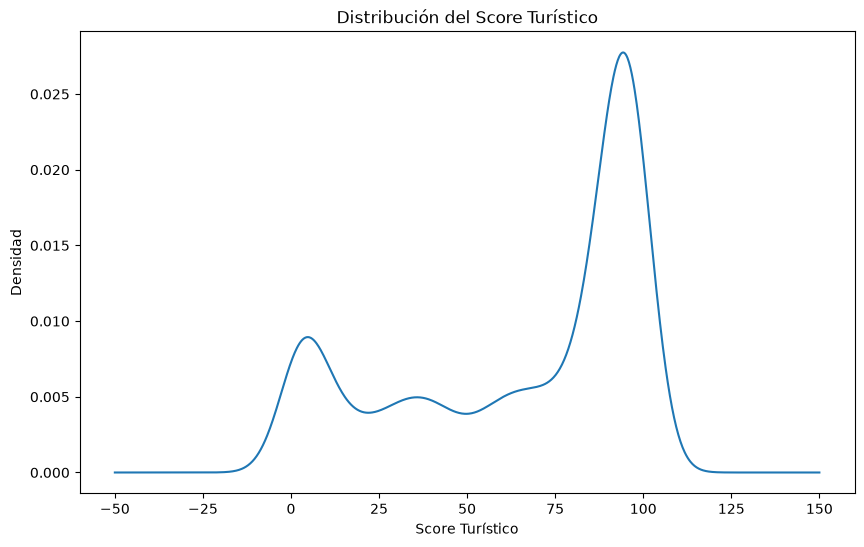

In [281]:
# Distribución del score turístico
plt.figure(figsize=(10, 6))
df['score_turistico'].plot(kind='density')
plt.xlabel('Score Turístico')
plt.ylabel('Densidad')
plt.title('Distribución del Score Turístico')
plt.show()

## 6. Discretizaciones

Las variables numéricas se agrupan en categorías para poder construir el minicubo del notebook 03.

In [282]:
# bedrooms → 4 categorías: 1, 2, 3 y 4 o más habitaciones
df['bedrooms_discretizada'] = pd.cut(df['bedrooms'], bins=[0, 1, 2, 3, float('inf')], labels=['1_hab', '2_hab', '3_hab', '4+_hab'])

In [283]:
# bathrooms → 3 categorías: 1 o menos, 2 y más de 2 baños
df['bathrooms_discretizada'] = pd.cut(df['bathrooms'], bins=[float('-inf'), 1, 2, float('inf')], labels=['1_baño', '2_baños', '3+_baños'])
df['bathrooms_discretizada'].value_counts(dropna=False).sort_index()

bathrooms_discretizada
1_baño      4138
2_baños     1286
3+_baños     227
Name: count, dtype: int64

In [284]:
# accommodates → 5 categorías: 1, 2, 3, 4 y 5 o más personas
df['accommodates_discretizada'] = pd.cut(df['accommodates'], bins=[float('-inf'), 1, 2, 3, 4,float('inf')], labels=['1_pers', '2_pers', '3_pers', '4_pers','+5_pers'])
df['accommodates_discretizada'].value_counts(dropna=False).sort_index()

accommodates_discretizada
1_pers      129
2_pers     1577
3_pers      664
4_pers     1960
+5_pers    1321
Name: count, dtype: int64

In [285]:
# beds → 5 categorías: 1 o menos, 2, 3, 4 y 5 o más camas
df['beds_discretizada'] = pd.cut(df['beds'], bins=[float('-inf'), 1, 2, 3, 4, float('inf')], labels=['1_cama', '2_camas', '3_camas', '4_camas', '5+_camas'])
df['beds_discretizada'].value_counts(dropna=False).sort_index()

beds_discretizada
1_cama      1781
2_camas     2059
3_camas     1057
4_camas      531
5+_camas     223
Name: count, dtype: int64

## 7. Margen bruto

**Margen bruto (%)** = ingresos anuales ÷ coste de adquisición × 100. Es la métrica de rentabilidad del proyecto.

In [286]:
# margen_bruto = ingresos anuales / coste de adquisición × 100
df['margen_bruto'] = df['ingresos_anuales'] / df['coste_adquisicion']*100
df['margen_bruto'] =df['margen_bruto'].round(2)

In [287]:
# Revisión de las variables de rentabilidad
df[['availability_365','estimated_occupancy_l365d','precio_noche_total','ingresos_anuales','coste_adquisicion','margen_bruto']].head(10)

,availability_365,estimated_occupancy_l365d,precio_noche_total,ingresos_anuales,coste_adquisicion,margen_bruto
1,348,120,82.0,9840.0,291412.50,3.38
6,174,150,228.0,34200.0,524542.50,6.52
9,85,150,67.0,10050.0,291412.50,3.45
10,22,192,122.0,23424.0,291412.50,8.04
11,61,174,133.0,23142.0,239400.00,9.67
13,145,255,184.0,46920.0,291412.50,16.10
17,252,102,114.0,11628.0,291412.50,3.99
18,84,255,209.0,53295.0,415106.25,12.84
19,280,144,37.0,5328.0,291412.50,1.83
20,97,198,133.0,26334.0,291412.50,9.04


In [288]:
# Margen bruto mediano y número de registros por distrito (de mayor a menor)
df.groupby('distrito').agg(
    margen_bruto=('margen_bruto', 'median'),
    n_registros=('margen_bruto', 'size')
).reset_index().sort_values('margen_bruto', ascending=False)

,distrito,margen_bruto,n_registros
12,Puente de Vallecas,14.280,134
2,Carabanchel,12.960,143
15,San Blas - Canillejas,12.300,103
19,Villa de Vallecas,12.080,21
9,Latina,11.845,86
20,Villaverde,11.675,24
6,Ciudad Lineal,11.550,177
18,Vicálvaro,10.910,15
11,Moratalaz,10.860,9
1,Barajas,10.285,36


## 8. Guardado del tablón analítico

In [243]:
# Se guarda el DataFrame como tabla tablon_analitico en la base de datos
with sqlite3.connect(ruta_db) as conn:
    df.to_sql('tablon_analitico', conn, if_exists='replace', index=False)
    n_filas = pd.read_sql("SELECT COUNT(*) AS n FROM tablon_analitico", conn)['n'][0]

print(f"tablon_analitico guardado: {n_filas} filas, {df.shape[1]} columnas")

tablon_analitico guardado: 7295 filas, 27 columnas
